# Predicting ATP match winners with Elo

Each player gets an **Elo rating** that goes up when they win and down when
they lose, by more when the result is a surprise. Before every match, the
two ratings give a win probability, and that is the prediction.

The ratings are built from **every ATP tour-level match** in the
[tennis-data.co.uk](http://www.tennis-data.co.uk/) files in `atp_data/`, one
file per year. (The Match Charting Project only has a sample of matches,
which would leave big gaps in players' histories.)

The notebook:

1. Loads and cleans the matches.
2. Builds the Elo step by step: a basic version, then surface-specific
   ratings, margin of victory and a best-of-5 adjustment.
3. Tunes each step on validation years and keeps it only if it helps, then
   tests the final model once on later years.
4. Compares against two baselines: picking the higher-ranked player, and the
   bookmakers' odds.

Every prediction uses only matches played before it.

## 1. Load the matches

In [1]:
import glob
import math
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", message=".*xlrd.*")
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

files = sorted(glob.glob(os.path.join("atp_data", "*.xls*")))
raw = pd.concat([pd.read_excel(f) for f in files], ignore_index=True)
print(f"{len(files)} files ({os.path.basename(files[0])} to "
      f"{os.path.basename(files[-1])}), {len(raw):,} matches")
raw.head(3)

5 files (2000.xls to 2004.xls), 14,518 matches


,ATP,Location,Tournament,Date,Series,Court,Surface,Round,Best of,Winner,Loser,WRank,LRank,W1,L1,...,CBL,GBW,GBL,IWW,IWL,SBW,SBL,B365W,B365L,B&WW,B&WL,EXW,EXL,PSW,PSL
0,1,Adelaide,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Dosedel S.,Ljubicic I.,63,77,6.0,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,Adelaide,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Enqvist T.,Clement A.,5,56,6.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,Adelaide,Australian Hardcourt Championships,2000-01-03,International,Outdoor,Hard,1st Round,3,Escude N.,Baccanello P.,40,655,6.0,7.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Cleaning:

- **Order**: older files only give each tournament's start date, so matches
  are ordered by date, then tournament, then round (first round before the
  final).
- **Walkovers** (no match played) are dropped.
- **Retirements** are kept and flagged; whether they should move the ratings
  is tuned later.
- **Rankings** that are missing or "NR" become missing values.
- **Games won** by each player are added up from the set scores, for the
  margin of victory.

In [2]:
ROUNDS = {"1st Round": 1, "2nd Round": 2, "3rd Round": 3, "4th Round": 4,
          "Round Robin": 5, "Quarterfinals": 6, "Semifinals": 7,
          "The Final": 8}

matches = raw[raw["Comment"] != "Walkover"].copy()
matches["Winner"] = matches["Winner"].str.strip()
matches["Loser"] = matches["Loser"].str.strip()
matches["Year"] = matches["Date"].dt.year
matches["round_order"] = matches["Round"].map(ROUNDS).fillna(0)
matches["retired"] = matches["Comment"] != "Completed"
for side in ("W", "L"):
    matches[f"{side}Rank"] = pd.to_numeric(matches[f"{side}Rank"],
                                           errors="coerce")
    matches[f"{side}games"] = matches[[f"{side}{k}" for k in range(1, 6)]
                                      ].apply(pd.to_numeric,
                                              errors="coerce").sum(axis=1)
matches = (matches.reset_index(names="row")
                  .sort_values(["Date", "ATP", "round_order", "row"])
                  .reset_index(drop=True))
print(f"{len(matches):,} matches after dropping "
      f"{len(raw) - len(matches)} walkovers; "
      f"{matches['retired'].sum()} retirements")
print(matches.groupby("Year").size().to_string())

14,469 matches after dropping 49 walkovers; 427 retirements
Year
2000    2949
2001    3051
2002    2799
2003    2800
2004    2870


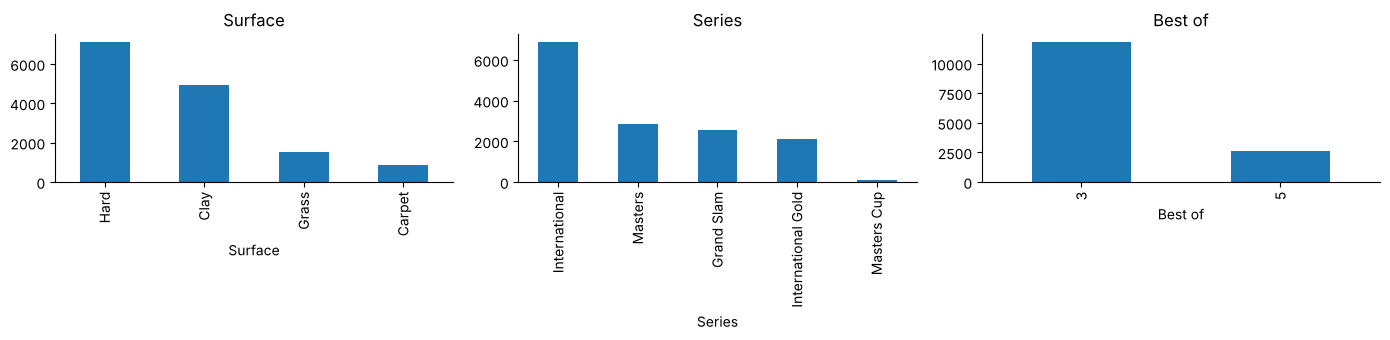

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, column in zip(axes, ["Surface", "Series", "Best of"]):
    matches[column].value_counts().plot(kind="bar", ax=ax)
    ax.set_title(column)
plt.tight_layout()

### Bookmaker probabilities

The files have decimal odds from several bookmakers (which ones changes
over the years). A bookmaker's win probability is 1 / odds; the two players'
probabilities add up to a bit more than 1 (the bookmaker's margin), so they
are scaled to add up to 1. Where several bookmakers have odds, their
probabilities are averaged.

In [4]:
books = sorted({c[:-1] for c in matches.columns
                if c.endswith("W") and f"{c[:-1]}L" in matches.columns
                and c not in ("W", "Winner")
                and c[:-1] not in ("", "Max")})
book_probs = []
for book in books:
    odds_w = pd.to_numeric(matches[f"{book}W"], errors="coerce")
    odds_l = pd.to_numeric(matches[f"{book}L"], errors="coerce")
    valid = (odds_w > 1) & (odds_l > 1)
    p = (1 / odds_w) / (1 / odds_w + 1 / odds_l)
    book_probs.append(p.where(valid))
matches["book_p"] = pd.concat(book_probs, axis=1).mean(axis=1)
print("Bookmakers:", ", ".join(books))
print(f"Matches with odds: {matches['book_p'].notna().mean():.1%}")

Bookmakers: B&W, B365, CB, EX, GB, IW, PS, SB
Matches with odds: 74.5%


## 2. The Elo model

For two players with ratings $R_A$ and $R_B$, the chance that A wins is

$$P(A) = \frac{1}{1 + 10^{(R_B - R_A)/400}}$$

so a 100-point gap is about a 64% favourite and 200 points about 76%. After
the match each rating moves by $K \times (\text{result} - P)$: the winner
gains what the loser loses, and a shock win moves the ratings more.

The extras, each switched on by a setting:

- **K that shrinks with experience**: $K = a / (n + 5)^c$ where $n$ is
  the number of matches the player has had rated. New players' ratings move
  fast and settle down as they play more.
- **Surface ratings**: every player also has a hard, clay, grass and carpet
  rating, updated only on that surface. The prediction uses a mix:
  $(1 - w) \times$ overall $+ \; w \times$ surface.
- **Margin of victory**: K is scaled by how dominant the win was, using the
  winner's share of games: $1 + \beta \times (\text{share} - 0.58)$, where
  0.58 is a typical winner's share.
- **Best of 5**: the better player is more likely to win over 5 sets. The
  best-of-3 probability is turned into a chance of winning each set, and
  that into a best-of-5 probability.
- **Retirements** move the ratings fully, or not at all.

New players start at 1500.

In [5]:
def to_best_of_5(p):
    """Best-of-3 win probability -> best-of-5, via the chance of winning a
    set (assuming each set is independent)."""
    lo, hi = 0.0, 1.0  # solve p = s^2 (3 - 2s) for s by bisection
    for _ in range(40):
        s = (lo + hi) / 2
        if s * s * (3 - 2 * s) < p:
            lo = s
        else:
            hi = s
    return s ** 3 * (10 - 15 * s + 6 * s * s)


def expected(r_a, r_b):
    return 1 / (1 + 10 ** ((r_b - r_a) / 400))


DEFAULTS = dict(k_scale=250, k_power=0.4, surface_weight=0.0,
                margin=0.0, best_of_5=False, use_retirements=True)


def run_elo(matches, return_ratings=False, **settings):
    """Win probability of the actual winner before every match.

    Returns an array aligned with matches. The ratings are updated after
    each match, so every prediction uses only earlier matches. With
    return_ratings, also returns everyone's final overall rating, number of
    rated matches and date of their last match.
    """
    s = {**DEFAULTS, **settings}
    overall, surface = {}, {}  # player or (player, surface) -> rating
    played, surface_played, last_seen = {}, {}, {}
    probs = np.empty(len(matches))
    columns = zip(matches["Winner"], matches["Loser"], matches["Surface"],
                  matches["Best of"], matches["retired"],
                  matches["Wgames"], matches["Lgames"], matches["Date"])
    for i, (w, l, surf, best_of, retired, wg, lg, day) in enumerate(columns):
        last_seen[w] = last_seen[l] = day
        rw, rl = overall.get(w, 1500.0), overall.get(l, 1500.0)
        sw = surface.get((w, surf), 1500.0)
        sl = surface.get((l, surf), 1500.0)
        weight = s["surface_weight"]
        p = expected((1 - weight) * rw + weight * sw,
                     (1 - weight) * rl + weight * sl)
        p_overall, p_surface = expected(rw, rl), expected(sw, sl)
        if s["best_of_5"] and best_of == 5:
            p = to_best_of_5(p)
            p_overall = to_best_of_5(p_overall)
            p_surface = to_best_of_5(p_surface)
        probs[i] = p

        if retired and not s["use_retirements"]:
            continue
        boost = 1.0
        if s["margin"] and not retired and wg + lg > 0:
            boost = max(0.0, 1 + s["margin"] * (wg / (wg + lg) - 0.58))

        def k(n):
            return s["k_scale"] / (n + 5) ** s["k_power"] * boost

        nw, nl = played.get(w, 0), played.get(l, 0)
        overall[w] = rw + k(nw) * (1 - p_overall)
        overall[l] = rl - k(nl) * (1 - p_overall)
        played[w], played[l] = nw + 1, nl + 1
        nsw = surface_played.get((w, surf), 0)
        nsl = surface_played.get((l, surf), 0)
        surface[(w, surf)] = sw + k(nsw) * (1 - p_surface)
        surface[(l, surf)] = sl - k(nsl) * (1 - p_surface)
        surface_played[(w, surf)] = nsw + 1
        surface_played[(l, surf)] = nsl + 1
    if return_ratings:
        return probs, pd.DataFrame({"rating": overall, "matches": played,
                                    "last_match": last_seen})
    return probs

### How predictions are scored

The data lists the winner first, so the prediction for a match is the
probability given to the player who actually won, $p$. That doesn't leak
the result: the model gives the same numbers whichever player is listed
first.

- **Accuracy**: the favourite won ($p > 0.5$).
- **Log loss**: $-\log p$, averaged. It punishes confident wrong
  predictions heavily; lower is better. A coin flip scores 0.693.
- **Brier score**: $(1 - p)^2$, averaged; lower is better. A coin flip
  scores 0.25.

In [6]:
def scores(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return {"accuracy": np.mean(p > 0.5), "log_loss": -np.mean(np.log(p)),
            "brier": np.mean((1 - p) ** 2), "matches": len(p)}

### Years for warm-up, tuning and testing

Ratings need a history before they mean anything, so the first years are
**warm-up** only: the ratings learn from them but they are not scored. The
remaining years are split in half by date: settings are chosen on the
**validation** years, and the final model is scored once on the **test**
years.

In [7]:
years = sorted(matches["Year"].unique())
n_warmup = max(2, len(years) // 5)
rest = years[n_warmup:]
n_validation = max(1, len(rest) // 2)
warmup, validation, test = (years[:n_warmup], rest[:n_validation],
                            rest[n_validation:])
is_val = matches["Year"].isin(validation).to_numpy()
is_test = matches["Year"].isin(test).to_numpy()
print(f"Warm-up {warmup[0]}-{warmup[-1]}, "
      f"validation {validation[0]}-{validation[-1]} "
      f"({is_val.sum():,} matches), "
      f"test {test[0]}-{test[-1]} ({is_test.sum():,} matches)")

Warm-up 2000-2001, validation 2002-2002 (2,799 matches), test 2003-2004 (5,670 matches)


## 3. Tuning, one step at a time

Each step adds one feature and tries a few settings for it, keeping the
others as already chosen. Settings are compared by **validation log loss**,
which uses every match's probability, not just right or wrong, so it is a
steadier guide than accuracy. A feature is kept only if it improves on the
step before.

In [8]:
def tune(base, grid):
    """Try every combination in grid on top of base; return the best
    settings by validation log loss, and a table of all tried."""
    keys = list(grid)
    tried = []
    for values in np.array(np.meshgrid(*grid.values()),
                           dtype=object).T.reshape(-1, len(keys)):
        settings = {**base, **dict(zip(keys, values))}
        p = run_elo(matches, **settings)
        tried.append({**dict(zip(keys, values)),
                      **scores(p[is_val])})
    table = pd.DataFrame(tried).sort_values("log_loss")
    best = {**base, **table.iloc[0][keys].to_dict()}
    return best, table


steps = {}

settings, table = tune(dict(DEFAULTS),
                       {"k_scale": [50, 75, 100, 150, 250, 350],
                        "k_power": [0.0, 0.2, 0.4, 0.6]})
steps["Basic Elo"] = dict(settings)
print("Basic Elo, best settings first (validation):")
table.head(8).round(4)

Basic Elo, best settings first (validation):


,k_scale,k_power,accuracy,log_loss,brier,matches
10,100,0.4,0.6381,0.6341,0.2220,2799
19,250,0.6,0.6392,0.6342,0.2219,2799
1,50,0.2,0.6370,0.6344,0.2221,2799
14,150,0.4,0.6388,0.6349,0.2222,2799
6,75,0.4,0.6406,0.6359,0.2227,2799
23,350,0.6,0.6399,0.6360,0.2225,2799
5,75,0.2,0.6402,0.6364,0.2228,2799
15,150,0.6,0.6370,0.6366,0.2231,2799


In [9]:
for name, grid in [
        ("+ surface ratings", {"surface_weight": [0.0, 0.25, 0.5, 0.75, 1.0]}),
        ("+ margin of victory", {"margin": [0.0, 1.0, 2.0, 4.0, 6.0, 8.0]}),
        ("+ best-of-5 adjustment", {"best_of_5": [False, True]}),
        ("+ retirements choice", {"use_retirements": [True, False]})]:
    settings, table = tune(settings, grid)
    steps[name] = dict(settings)
    print(f"{name}:")
    print(table.round(4).to_string(index=False), "\n")

+ surface ratings:
 surface_weight  accuracy  log_loss  brier  matches
           0.25    0.6392    0.6314 0.2207     2799
           0.50    0.6402    0.6314 0.2207     2799
           0.00    0.6381    0.6341 0.2220     2799
           0.75    0.6374    0.6343 0.2219     2799
           1.00    0.6249    0.6400 0.2246     2799 



+ margin of victory:
 margin  accuracy  log_loss  brier  matches
    6.0    0.6431    0.6272 0.2189     2799
    4.0    0.6409    0.6275 0.2191     2799
    8.0    0.6409    0.6278 0.2191     2799
    2.0    0.6424    0.6288 0.2196     2799
    1.0    0.6402    0.6299 0.2201     2799
    0.0    0.6392    0.6314 0.2207     2799 

+ best-of-5 adjustment:
 best_of_5  accuracy  log_loss  brier  matches
      True    0.6424    0.6272 0.2189     2799
     False    0.6431    0.6272 0.2189     2799 



+ retirements choice:
 use_retirements  accuracy  log_loss  brier  matches
            True    0.6424    0.6272 0.2189     2799
           False    0.6384    0.6289 0.2197     2799 



In [10]:
pd.DataFrame(steps).T

,k_scale,k_power,surface_weight,margin,best_of_5,use_retirements
Basic Elo,100.0,0.4,0.0,0.0,False,True
+ surface ratings,100.0,0.4,0.25,0.0,False,True
+ margin of victory,100.0,0.4,0.25,6.0,False,True
+ best-of-5 adjustment,100.0,0.4,0.25,6.0,True,True
+ retirements choice,100.0,0.4,0.25,6.0,True,True


## 4. Results on the test years

Each step's settings scored on the test years, which were not used for any
choices. Alongside:

- **Higher ranking**: the higher-ranked player wins. It gives no
  probability, so only its accuracy is shown. An unranked player counts as
  ranked below everyone.
- **Bookmakers**: the averaged bookmaker probability, on the test matches
  that have odds.

In [11]:
rows = {}
for name, step_settings in steps.items():
    rows[name] = scores(run_elo(matches, **step_settings)[is_test])
final = steps[list(steps)[-1]]
final_p = run_elo(matches, **final)
matches["elo_p"] = final_p

tested = matches[is_test]
# An unranked player counts as ranked below everyone.
ranked = (tested["WRank"].fillna(10_000) < tested["LRank"].fillna(10_000))
rows["Higher ranking"] = {"accuracy": ranked.mean(),
                          "matches": len(tested)}
with_odds = tested["book_p"].notna()
rows["Bookmakers (matches with odds)"] = scores(tested.loc[with_odds,
                                                            "book_p"])
rows["Final Elo (same matches)"] = scores(tested.loc[with_odds, "elo_p"])
results = pd.DataFrame(rows).T
results["accuracy"] = (results["accuracy"] * 100).round(1)
print(f"Test years {test[0]}-{test[-1]} (accuracy in %):")
results.round(4)

Test years 2003-2004 (accuracy in %):


,accuracy,log_loss,brier,matches
Basic Elo,64.6,0.6255,0.2181,5670.0
+ surface ratings,64.7,0.6221,0.2165,5670.0
+ margin of victory,65.6,0.6173,0.2144,5670.0
+ best-of-5 adjustment,65.7,0.6162,0.2140,5670.0
+ retirements choice,65.7,0.6162,0.2140,5670.0
Higher ranking,64.1,NaN,NaN,5670.0
Bookmakers (matches with odds),68.6,0.5873,0.2011,5547.0
Final Elo (same matches),65.7,0.6159,0.2138,5547.0


### Calibration

A well-calibrated model's 70% favourites should win about 70% of the time.
Each point below groups test matches by the predicted chance of the
favourite.

,predicted,won,matches
elo_p,,,
"(0.5, 0.55]",0.525,0.530,1035
"(0.55, 0.6]",0.574,0.551,937
"(0.6, 0.65]",0.624,0.635,907
"(0.65, 0.7]",0.675,0.661,762
"(0.7, 0.75]",0.723,0.723,639
"(0.75, 0.8]",0.775,0.759,544
"(0.8, 0.85]",0.823,0.792,409
"(0.85, 0.9]",0.873,0.848,277
"(0.9, 0.95]",0.922,0.906,128


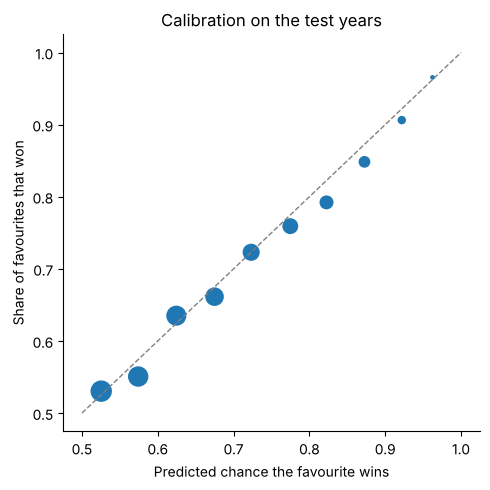

In [12]:
fav_p = np.maximum(tested["elo_p"], 1 - tested["elo_p"])
fav_won = tested["elo_p"] > 0.5
bins = pd.cut(fav_p, np.arange(0.5, 1.0001, 0.05))
calibration = pd.DataFrame({"predicted": fav_p, "won": fav_won}) \
    .groupby(bins, observed=True).agg(predicted=("predicted", "mean"),
                                      won=("won", "mean"),
                                      matches=("won", "size"))
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0.5, 1], [0.5, 1], color="grey", linestyle="--", linewidth=1)
ax.scatter(calibration["predicted"], calibration["won"],
           s=calibration["matches"] / 5)
ax.set_xlabel("Predicted chance the favourite wins")
ax.set_ylabel("Share of favourites that won")
ax.set_title("Calibration on the test years")
plt.tight_layout()
calibration.round(3)

## 5. Current ratings

The top of the final overall ratings, after the last match in the data: players with 50+ rated matches who played in the final year.

In [13]:
_, table = run_elo(matches, return_ratings=True, **final)
active = (table["matches"] >= 50) & (table["last_match"].dt.year == years[-1])
print(f"After {matches['Date'].max():%d %b %Y}:")
table[active].sort_values("rating", ascending=False).head(15).round({"rating": 0})

After 21 Nov 2004:


,rating,matches,last_match
Federer R.,2056.0,362,2004-11-21
Roddick A.,1938.0,304,2004-11-20
Hewitt L.,1935.0,348,2004-11-21
Agassi A.,1918.0,283,2004-10-31
Coria G.,1863.0,213,2004-11-19
Moya C.,1832.0,329,2004-11-19
Safin M.,1813.0,323,2004-11-20
Henman T.,1812.0,315,2004-11-20
Nalbandian D.,1798.0,191,2004-10-31
Haas T.,1790.0,237,2004-11-04


## Summary

The tables above show how much each step adds on the test years and how the
final Elo compares with the rankings and the bookmakers. Things to try next:

- **More years**: add more files to `atp_data/` and rerun; the warm-up,
  validation and test years adjust automatically.
- **Tournament level**: a larger K for Grand Slams and Masters.
- **Inactivity**: pull a player's rating back towards average after a long
  injury break.
- **Charting data**: serve and return ratings from the Match Charting
  Project, for the matches it covers.